# Лабораторная работа №1. Вариант 10
## Классификация текста: от классического ML до дообучения трансформера и анализа переобучения

- **Датасет:** `community-datasets/yahoo_answers_topics` — вопросы с Yahoo Answers
- **Задача:** определить тему вопроса, **10 классов**
- **MAX_LEN:** 64 токена
- **Эксперимент (шаг 3.4):** обучение только на заголовке вопроса

> **Как запустить.** Локально: VS Code / Jupyter с ядром из своего venv. Или Google Colab → *Среда выполнения → Сменить среду выполнения → T4 GPU*.
> Затем *Среда выполнения → Выполнить все*. Полный прогон занимает около 10–15 минут.

In [ ]:
# Установка библиотек в окружение этого ноутбука.
# Если torch не видит видеокарту — ставим сборку PyTorch с CUDA (на Windows обычный pip ставит версию без CUDA).
# В Colab torch с CUDA уже есть, поэтому там шаг пропускается.
import sys, subprocess

def torch_cuda():
    r = subprocess.run([sys.executable, "-c", "import torch; print(torch.cuda.is_available())"],
                       capture_output=True, text=True)
    return r.stdout.strip() == "True"

def pip(*args):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *args],
                       capture_output=True, text=True)
    if r.returncode != 0:
        print(r.stderr[-1500:])
    return r.returncode == 0

if torch_cuda():
    print("PyTorch с CUDA уже установлен")
else:
    print("Ставлю PyTorch с поддержкой CUDA (около 3 ГБ, несколько минут)...")
    for idx in ["cu128", "cu126", "cu130"]:
        if pip("torch", "--index-url", f"https://download.pytorch.org/whl/{idx}") and torch_cuda():
            print("готово, сборка", idx)
            break

print("Ставлю остальные библиотеки...")
pip("transformers", "datasets", "accelerate", "scikit-learn", "matplotlib", "pandas")
print("PyTorch видит видеокарту:", torch_cuda())

PyTorch с CUDA уже установлен
Ставлю остальные библиотеки...
PyTorch видит видеокарту: True


## Подготовка

In [ ]:
VARIANT = 10                     # номер своего варианта, 1..30
SEED = 1000 + VARIANT
EPOCHS, LR = 5, 2e-5             # варианты 13 и 14 переопределяют в своём коде

import random, time
import numpy as np
import torch
from datasets import load_dataset, concatenate_datasets

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if torch.cuda.is_available():
    print("Видеокарта:", torch.cuda.get_device_name(0))
elif torch.backends.mps.is_available():
    print("Видеокарта: Apple MPS")
else:
    print("Видеокарты НЕТ — обучение пойдёт на процессоре, в 10–30 раз дольше")

Видеокарта: NVIDIA GeForce RTX 4060 Ti


In [ ]:
def to_pool(parts, text_fn, label_fn):
    '''Склеивает части датасета и приводит их к двум колонкам: text, label.'''
    d = concatenate_datasets(parts)
    d = d.map(lambda ex: {"text": text_fn(ex), "label": label_fn(ex)},
              remove_columns=d.column_names)
    return d.filter(lambda ex: bool(ex["text"]) and ex["label"] != -1)

### Данные варианта 10

Текст примера склеивается из трёх полей: заголовок вопроса, текст вопроса и лучший ответ.
Обучающая часть датасета большая (около 1.4 млн вопросов), поэтому сборка `pool` занимает пару минут.

In [ ]:
ds = load_dataset("community-datasets/yahoo_answers_topics")
full_text = lambda ex: " ".join(x for x in (ex["question_title"],
    ex["question_content"], ex["best_answer"]) if x)
pool = to_pool([ds["train"]], full_text, lambda ex: ex["topic"])
LABELS = ds["train"].features["topic"].names          # 10 тем
MAX_LEN = 64

print("Классы:", LABELS)

Классы: ['Society & Culture', 'Science & Mathematics', 'Health', 'Education & Reference', 'Computers & Internet', 'Sports', 'Business & Finance', 'Entertainment & Music', 'Family & Relationships', 'Politics & Government']


In [ ]:
# pool, LABELS, MAX_LEN заданы кодом варианта (раздел 2)
N_POOL_FULL = len(pool)          # запоминаем размер — пригодится для проверки в шаге 3.4
N_MAX = 2000 if VARIANT == 28 else 5000
pool = pool.shuffle(seed=SEED).select(range(min(N_MAX, len(pool))))
a = pool.train_test_split(test_size=0.30, seed=SEED)
b = a["test"].train_test_split(test_size=0.50, seed=SEED)
train_ds, val_ds, test_ds = a["train"], b["train"], b["test"]
print(len(train_ds), len(val_ds), len(test_ds))

3500 750 750


# Задание 1. Разведка данных и классический baseline

### 1.1. Распределение классов в обучающей части

,класс,примеров,"доля, %"
0,Society & Culture,367,10.5
1,Science & Mathematics,357,10.2
2,Health,357,10.2
3,Education & Reference,327,9.3
4,Computers & Internet,337,9.6
5,Sports,319,9.1
6,Business & Finance,339,9.7
7,Entertainment & Music,347,9.9
8,Family & Relationships,382,10.9
9,Politics & Government,368,10.5


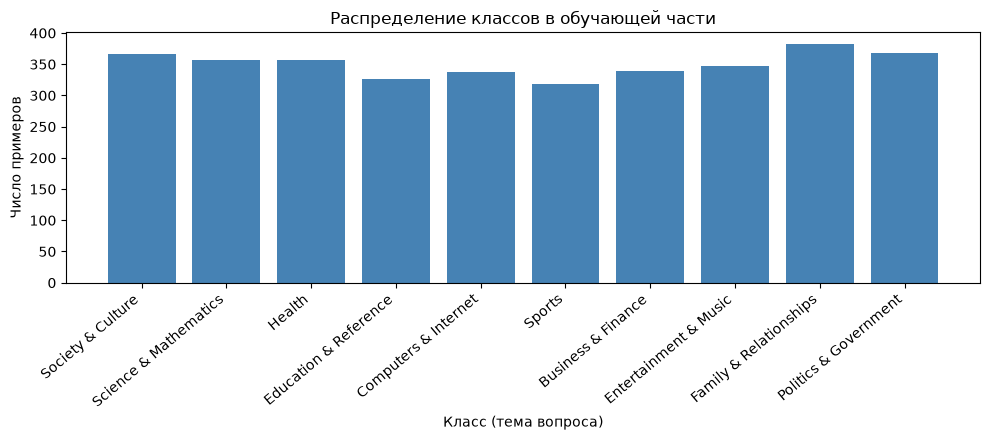

Самый частый класс: Family & Relationships (382), самый редкий: Sports (319)
Отношение самого частого к самому редкому: 1.20


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

cnt = Counter(train_ds["label"])
dist = pd.DataFrame({
    "класс": LABELS,
    "примеров": [cnt[k] for k in range(len(LABELS))],
})
dist["доля, %"] = (100 * dist["примеров"] / len(train_ds)).round(1)
display(dist)

plt.figure(figsize=(10, 4.5))
plt.bar(range(len(LABELS)), dist["примеров"], color="steelblue")
plt.xticks(range(len(LABELS)), LABELS, rotation=40, ha="right")
plt.xlabel("Класс (тема вопроса)")
plt.ylabel("Число примеров")
plt.title("Распределение классов в обучающей части")
plt.tight_layout(); plt.show()

print(f"Самый частый класс: {dist.loc[dist['примеров'].idxmax(), 'класс']} "
      f"({dist['примеров'].max()}), самый редкий: {dist.loc[dist['примеров'].idxmin(), 'класс']} "
      f"({dist['примеров'].min()})")
print(f"Отношение самого частого к самому редкому: {dist['примеров'].max() / dist['примеров'].min():.2f}")

### 1.2. Длины текстов в токенах DistilBERT

Медиана длины: 88 токенов, среднее: 133, максимум: 1378
Доля текстов длиннее MAX_LEN = 64: 63.9%  (будут обрезаны)


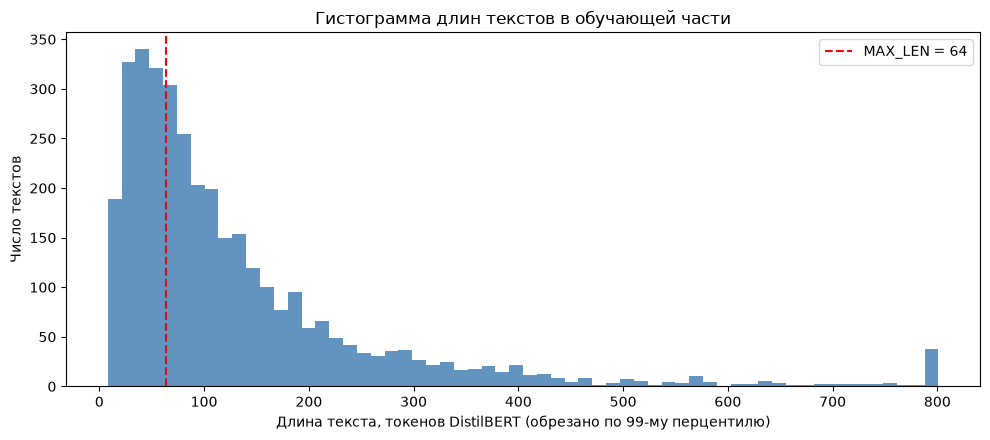

In [ ]:
from transformers import AutoTokenizer
import transformers
transformers.logging.set_verbosity_error()   # без предупреждений о длинных текстах

model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# длина с учётом служебных токенов [CLS] и [SEP] — именно её обрезает truncation
lengths = np.array([len(ids) for ids in tokenizer(list(train_ds["text"]), truncation=False)["input_ids"]])
share_long = (lengths > MAX_LEN).mean()

print(f"Медиана длины: {np.median(lengths):.0f} токенов, среднее: {lengths.mean():.0f}, максимум: {lengths.max()}")
print(f"Доля текстов длиннее MAX_LEN = {MAX_LEN}: {share_long:.1%}  (будут обрезаны)")

clip = np.percentile(lengths, 99)
plt.figure(figsize=(10, 4.5))
plt.hist(np.minimum(lengths, clip), bins=60, color="steelblue", alpha=0.85)
plt.axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.xlabel("Длина текста, токенов DistilBERT (обрезано по 99-му перцентилю)")
plt.ylabel("Число текстов")
plt.title("Гистограмма длин текстов в обучающей части")
plt.legend(); plt.tight_layout(); plt.show()

### 1.3. Baseline: TF-IDF + логистическая регрессия

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

t0 = time.time()
vec = TfidfVectorizer(max_features=10000)
X_train = vec.fit_transform(train_ds["text"])
X_test = vec.transform(test_ds["text"])
clf = LogisticRegression(max_iter=1000).fit(X_train, train_ds["label"])
pred = clf.predict(X_test)
print(f"время обучения: {time.time() - t0:.1f} с")
print("Accuracy:", accuracy_score(test_ds["label"], pred))
print("Macro-F1:", f1_score(test_ds["label"], pred, average="macro"))

base_time = time.time() - t0
base_acc = accuracy_score(test_ds["label"], pred)
base_f1 = f1_score(test_ds["label"], pred, average="macro")

время обучения: 1.1 с
Accuracy: 0.5906666666666667
Macro-F1: 0.5810696313889878


### Вывод по заданию 1

Обучающая часть содержит 3500 примеров, классы распределены почти равномерно: от 319 (Sports) до 382 (Family & Relationships) примеров на класс, отношение самого частого к самому редкому — 1.20. Дисбаланса нет, поэтому Accuracy и Macro-F1 будут близки.
Тексты длинные и с тяжёлым хвостом: медиана 88 токенов, среднее 133, максимум 1378. При MAX_LEN = 64 обрезается **63.9%** текстов — трансформер увидит в основном заголовок и начало вопроса, а лучший ответ почти всегда будет отрезан.
Baseline TF-IDF + логистическая регрессия обучается примерно за 1 с и даёт на тесте **Accuracy = 0.591, Macro-F1 = 0.581** — в шесть раз лучше случайного угадывания (0.10 для 10 классов).

# Задание 2. Дообучение предобученного трансформера DistilBERT

In [ ]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding,
                          EarlyStoppingCallback)

model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name, num_labels=len(LABELS))


def encode(d):
    d = d.map(lambda b: tokenizer(b["text"], truncation=True, max_length=MAX_LEN),
              batched=True)
    return d.rename_column("label", "labels").remove_columns(["text"])


train_enc, val_enc, test_enc = encode(train_ds), encode(val_ds), encode(test_ds)


def compute_metrics(p):
    pred = p.predictions.argmax(-1)
    return {"accuracy": accuracy_score(p.label_ids, pred),
            "f1_macro": f1_score(p.label_ids, pred, average="macro")}


args = TrainingArguments(
    output_dir="./out", num_train_epochs=EPOCHS, learning_rate=LR,
    per_device_train_batch_size=16, per_device_eval_batch_size=64,
    eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="f1_macro",
    save_total_limit=1, seed=SEED, report_to="none",
    fp16=torch.cuda.is_available())
trainer = Trainer(
    model=model, args=args, train_dataset=train_enc, eval_dataset=val_enc,
    processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
t0 = time.time()
trainer.train()
print(f"время обучения: {time.time() - t0:.1f} с")
bert_time = time.time() - t0
test_res = trainer.evaluate(test_enc, metric_key_prefix="test")
print(test_res)

# кривые обучения: train loss и val loss по эпохам
hist = trainer.state.log_history
train_loss = [h["loss"] for h in hist if "loss" in h]
val_loss = [h["eval_loss"] for h in hist if "eval_loss" in h]

W1029 01:52:11.586000 30196 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Map: 100%|██████████| 750/750 [00:00<00:00, 10688.59 examples/s]


{'loss': '1.621', 'grad_norm': '8.037', 'learning_rate': '1.602e-05', 'epoch': '1'}
{'eval_loss': '1.112', 'eval_accuracy': '0.6813', 'eval_f1_macro': '0.6619', 'eval_runtime': '0.251', 'eval_samples_per_second': '2988', 'eval_steps_per_second': '47.81', 'epoch': '1'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.57it/s]


{'loss': '0.9597', 'grad_norm': '9.071', 'learning_rate': '1.202e-05', 'epoch': '2'}
{'eval_loss': '0.976', 'eval_accuracy': '0.6973', 'eval_f1_macro': '0.6959', 'eval_runtime': '0.2592', 'eval_samples_per_second': '2893', 'eval_steps_per_second': '46.3', 'epoch': '2'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.43it/s]


...

{'loss': '0.5877', 'grad_norm': '7.263', 'learning_rate': '4.018e-06', 'epoch': '4'}
{'eval_loss': '0.958', 'eval_accuracy': '0.7093', 'eval_f1_macro': '0.7047', 'eval_runtime': '0.2469', 'eval_samples_per_second': '3037', 'eval_steps_per_second': '48.59', 'epoch': '4'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.71it/s]


{'loss': '0.497', 'grad_norm': '5.861', 'learning_rate': '1.826e-08', 'epoch': '5'}
{'eval_loss': '0.968', 'eval_accuracy': '0.7013', 'eval_f1_macro': '0.6968', 'eval_runtime': '0.2523', 'eval_samples_per_second': '2973', 'eval_steps_per_second': '47.57', 'epoch': '5'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.52it/s]


{'train_runtime': '56.69', 'train_samples_per_second': '308.7', 'train_steps_per_second': '19.32', 'train_loss': '0.8811', 'epoch': '5'}
время обучения: 57.0 с
{'test_loss': '0.9832', 'test_accuracy': '0.6933', 'test_f1_macro': '0.6859', 'test_runtime': '0.26', 'test_samples_per_second': '2884', 'test_steps_per_second': '46.15', 'epoch': '5'}
{'test_loss': 0.983212947845459, 'test_accuracy': 0.6933333333333334, 'test_f1_macro': 0.6858815846867908, 'test_runtime': 0.26, 'test_samples_per_second': 2884.071, 'test_steps_per_second': 46.145, 'epoch': 5.0}


### 2.1. Кривые обучения

,train loss,val loss,val Accuracy,val Macro-F1
эпоха,,,,
1,1.6215,1.1119,0.6813,0.6619
2,0.9597,0.9760,0.6973,0.6959
3,0.7399,0.9574,0.7013,0.6972
4,0.5877,0.9580,0.7093,0.7047
5,0.4970,0.9680,0.7013,0.6968


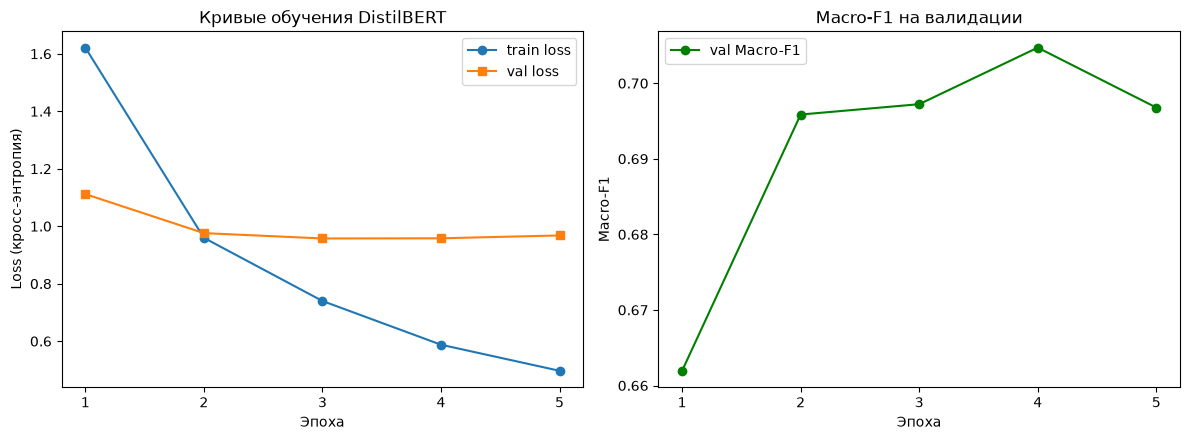

In [ ]:
def curves(hist):
    '''Таблица по эпохам: train loss, val loss, val Accuracy, val Macro-F1.'''
    rows = {}
    for h in hist:
        if "epoch" not in h:
            continue
        e = int(round(h["epoch"]))
        if "loss" in h:
            rows.setdefault(e, {})["train loss"] = h["loss"]
        if "eval_loss" in h:
            rows.setdefault(e, {}).update({"val loss": h["eval_loss"],
                                           "val Accuracy": h["eval_accuracy"],
                                           "val Macro-F1": h["eval_f1_macro"]})
    df = pd.DataFrame.from_dict(rows, orient="index").sort_index()
    df.index.name = "эпоха"
    return df.dropna(subset=["val loss"])

ep = curves(hist)
display(ep.round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(ep.index, ep["train loss"], "o-", label="train loss")
ax[0].plot(ep.index, ep["val loss"], "s-", label="val loss")
ax[0].set_xlabel("Эпоха"); ax[0].set_ylabel("Loss (кросс-энтропия)")
ax[0].set_title("Кривые обучения DistilBERT"); ax[0].set_xticks(ep.index); ax[0].legend()
ax[1].plot(ep.index, ep["val Macro-F1"], "o-", color="green", label="val Macro-F1")
ax[1].set_xlabel("Эпоха"); ax[1].set_ylabel("Macro-F1")
ax[1].set_title("Macro-F1 на валидации"); ax[1].set_xticks(ep.index); ax[1].legend()
plt.tight_layout(); plt.show()

### 2.2. Сравнение с baseline

In [ ]:
cmp = pd.DataFrame([
    {"модель": "TF-IDF + LogReg", "Accuracy": base_acc, "Macro-F1": base_f1, "время, с": base_time},
    {"модель": "DistilBERT",      "Accuracy": test_res["test_accuracy"],
     "Macro-F1": test_res["test_f1_macro"], "время, с": bert_time},
])
display(cmp.round({"Accuracy": 4, "Macro-F1": 4, "время, с": 1}))

diff = 100 * (test_res['test_f1_macro'] - base_f1)
print(f"Разница Macro-F1 (DistilBERT − baseline): {diff:+.1f} п.п. — "
      f"{'трансформер лучше' if diff > 0 else 'baseline не хуже'}; "
      f"DistilBERT обучается в {bert_time / base_time:.0f} раз дольше")

,модель,Accuracy,Macro-F1,"время, с"
0,TF-IDF + LogReg,0.5907,0.5811,1.3
1,DistilBERT,0.6933,0.6859,57.0


Разница Macro-F1 (DistilBERT − baseline): +10.5 п.п. — трансформер лучше; DistilBERT обучается в 43 раз дольше


### Вывод по заданию 2

DistilBERT обучался все 5 эпох за 57 с и показал на тесте **Accuracy = 0.693, Macro-F1 = 0.686**. По сравнению с baseline качество выросло на **10.5 п.п.** Macro-F1 (0.581 → 0.686), но обучение заняло в ~43 раза больше времени и потребовало видеокарты.
Важно, что трансформер видит только первые 64 токена, а TF-IDF — весь текст, и всё равно выигрывает: сказывается предобучение, модель понимает смысл фраз, а не только совпадение слов.
Train loss монотонно падает с 1.62 до 0.50, а val loss снижается только до 3-й эпохи (0.957), затем перестаёт падать и слегка растёт до 0.968: модель продолжает подстраиваться под обучающие примеры, не улучшая обобщение.

# Задание 3. Анализ переобучения и ошибок

### Шаг 3.1. Переобучение по кривым

In [ ]:
ep_min_loss = int(ep["val loss"].idxmin())
ep_max_f1 = int(ep["val Macro-F1"].idxmax())
last = int(ep.index.max())
gap = ep.loc[last, "val loss"] - ep.loc[last, "train loss"]
stopped_early = last < EPOCHS

print(f"Минимум val loss:        эпоха {ep_min_loss}  (val loss = {ep['val loss'].min():.4f})")
print(f"Максимум val Macro-F1:   эпоха {ep_max_f1}  (Macro-F1 = {ep['val Macro-F1'].max():.4f})")
print(f"Эпохи совпадают: {'да' if ep_min_loss == ep_max_f1 else 'нет'}")
print(f"Разрыв val loss − train loss на последней ({last}-й) эпохе: "
      f"{ep.loc[last, 'val loss']:.4f} − {ep.loc[last, 'train loss']:.4f} = {gap:.4f}")
if stopped_early:
    print(f"Ранняя остановка СРАБОТАЛА: обучение остановлено после {last}-й эпохи из {EPOCHS} "
          f"(Macro-F1 не рос две эпохи после {ep_max_f1}-й)")
else:
    print(f"Ранняя остановка НЕ сработала: пройдены все {EPOCHS} эпох")
print(f"Для теста загружена лучшая модель — эпоха {ep_max_f1}")

Минимум val loss:        эпоха 3  (val loss = 0.9574)
Максимум val Macro-F1:   эпоха 4  (Macro-F1 = 0.7047)
Эпохи совпадают: нет
Разрыв val loss − train loss на последней (5-й) эпохе: 0.9680 − 0.4970 = 0.4710
Ранняя остановка НЕ сработала: пройдены все 5 эпох
Для теста загружена лучшая модель — эпоха 4


**Сравнение с типичной картиной переобучения из задания**

| Эпоха | Train loss | Val loss |
|---|---|---|
| 1 | 0.95 | 0.62 |
| 2 | 0.55 | 0.48 (минимум) |
| 3 | 0.32 | 0.51 |
| 4 | 0.18 | 0.66 |
| 5 | 0.12 | 0.85 |

В типичной картине train loss падает всё время, а val loss после минимума начинает расти: модель запоминает обучающие примеры вместо того, чтобы обобщать.

Минимум val loss — на **3-й эпохе** (0.9574), максимум val Macro-F1 — на **4-й** (0.7047): эпохи не совпадают. На 4-й эпохе правильных ответов стало больше, но в ошибках модель стала чуть увереннее, поэтому loss почти не изменился (+0.0006).
Разрыв val loss − train loss на последней эпохе: 0.968 − 0.497 = **0.471** — переобучение умеренное: train loss продолжает падать, val loss после минимума слегка растёт.
Ранняя остановка **не сработала**: Macro-F1 рос до 4-й эпохи, после неё прошла только одна эпоха без улучшения, а нужно две подряд. Для теста загружена лучшая модель с 4-й эпохи.
По сравнению с типичной картиной из таблицы, где val loss после минимума вырос с 0.48 до 0.85 (на 77%), у нас рост всего на 1% (0.957 → 0.968): переобучение только начинается. Пяти эпох при LR = 2·10⁻⁵ не хватило, чтобы модель успела запомнить 3500 примеров.

### Шаг 3.2. Матрица ошибок

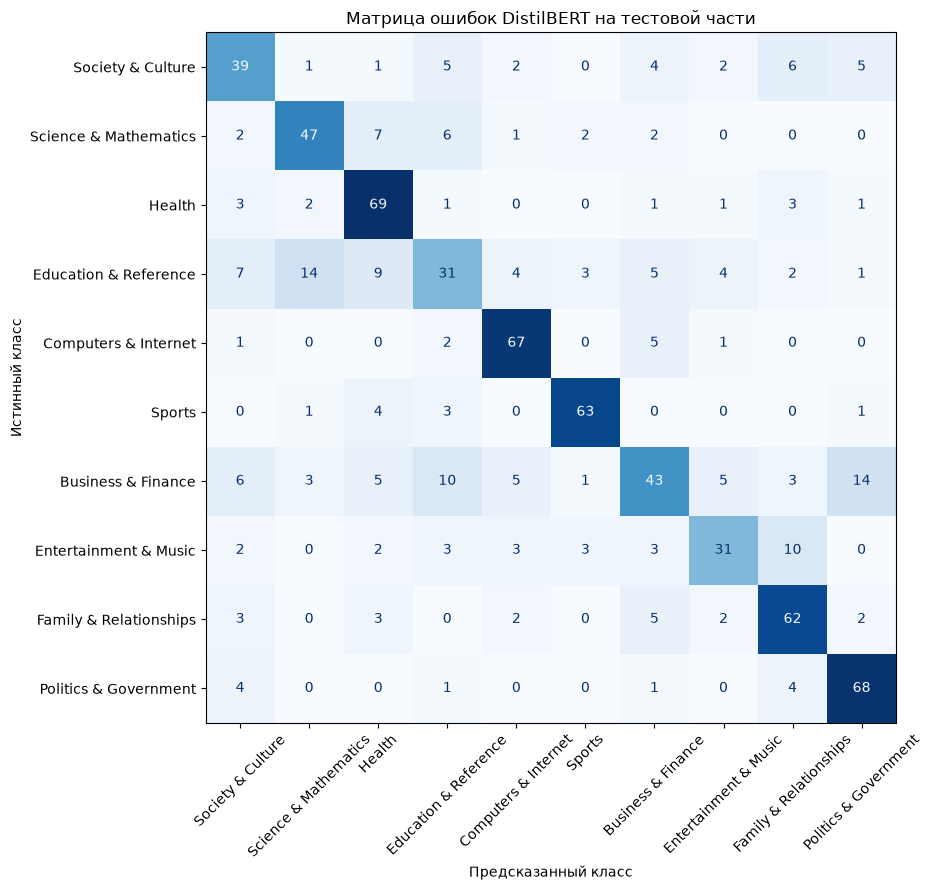

Пять самых частых ошибок:


,истина,предсказано,ошибок
0,Education & Reference,Science & Mathematics,14
1,Business & Finance,Politics & Government,14
2,Business & Finance,Education & Reference,10
3,Entertainment & Music,Family & Relationships,10
4,Education & Reference,Health,9


Чаще всего модель путает «Science & Mathematics» и «Education & Reference»: 6 + 14 = 20 ошибок в обе стороны

F1 по классам:


,класс,F1
3,Education & Reference,0.437
6,Business & Finance,0.524
0,Society & Culture,0.591
7,Entertainment & Music,0.602
1,Science & Mathematics,0.696
8,Family & Relationships,0.734
2,Health,0.762
9,Politics & Government,0.800
4,Computers & Internet,0.838
5,Sports,0.875


In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

out = trainer.predict(test_enc)
logits = out.predictions
probs = torch.softmax(torch.tensor(logits, dtype=torch.float32), dim=-1).numpy()
y_true = np.array(out.label_ids)
y_pred = probs.argmax(-1)

cm = confusion_matrix(y_true, y_pred, labels=range(len(LABELS)))
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
ax.set_xlabel("Предсказанный класс"); ax.set_ylabel("Истинный класс")
ax.set_title("Матрица ошибок DistilBERT на тестовой части")
plt.tight_layout(); plt.show()

# самые частые пары путаницы (вне диагонали)
pairs = []
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        if i != j and cm[i, j] > 0:
            pairs.append({"истина": LABELS[i], "предсказано": LABELS[j], "ошибок": int(cm[i, j])})
pairs = pd.DataFrame(pairs).sort_values("ошибок", ascending=False).head(5).reset_index(drop=True)
print("Пять самых частых ошибок:")
display(pairs)

# пара с наибольшей путаницей в обе стороны
sym = cm + cm.T
np.fill_diagonal(sym, 0)
pi, pj = np.unravel_index(sym.argmax(), sym.shape)
print(f"Чаще всего модель путает «{LABELS[pi]}» и «{LABELS[pj]}»: "
      f"{cm[pi, pj]} + {cm[pj, pi]} = {sym[pi, pj]} ошибок в обе стороны")

per_class = f1_score(y_true, y_pred, average=None)
print("\nF1 по классам:")
display(pd.DataFrame({"класс": LABELS, "F1": per_class.round(3)}).sort_values("F1"))

Чаще всего модель путает **«Science & Mathematics» и «Education & Reference»** — 20 ошибок в обе стороны (14 вопросов из Education отнесены к Science и 6 наоборот). Учебные вопросы — задачи по математике и физике, домашние задания — по лексике (числа, формулы, термины) неотличимы от научных. Граница между этими темами определяется не содержанием, а тем, в какой раздел автор положил вопрос.
Education & Reference вообще самый трудный класс (**F1 = 0.437**): это «сборный» раздел без собственной лексики, его вопросы похожи и на науку, и на здоровье, и на компьютеры. Второй по трудности — Business & Finance (0.524), его путают с Politics & Government (14 ошибок: налоги, экономика, законы). Легче всего даются темы с узнаваемыми терминами: Sports (0.875) и Computers & Internet (0.838).

### Шаг 3.3. Разбор трёх ошибок

In [ ]:
# три самых уверенных ошибки: модель ошиблась, будучи уверенной в неверном ответе
wrong = np.where(y_pred != y_true)[0]
wrong = wrong[np.argsort(-probs[wrong].max(-1))][:3]

for n, k in enumerate(wrong, 1):
    text = test_ds[int(k)]["text"]
    print("=" * 90)
    print(f"ОШИБКА {n}")
    print(f"Текст: {text[:400]}{'...' if len(text) > 400 else ''}")
    print(f"Истинная метка:   {LABELS[y_true[k]]}  (вероятность {probs[k, y_true[k]]:.3f})")
    print(f"Предсказано:      {LABELS[y_pred[k]]}  (вероятность {probs[k, y_pred[k]]:.3f})")
    print("Вероятности классов:")
    for c in np.argsort(-probs[k]):
        mark = "  ← истина" if c == y_true[k] else ("  ← предсказано" if c == y_pred[k] else "")
        print(f"    {LABELS[c]:<26} {probs[k, c]:.3f}{mark}")

ОШИБКА 1
Текст: I am so frustrated . Can any one help me here Please? A baseball thrown in the air at an angle of 0.5% below the horizontal at 90 miles per hour towards home plate which is 60 feet from the pitching rubber. the pitcher releases the ball 5 feet above the ground and 4 feet in front of the pitching rubber. recall: 1 mile=5280 ft\n\na) write the parametric equations for the path of the ball\n\nb) how ...
Истинная метка:   Education & Reference  (вероятность 0.004)
Предсказано:      Sports  (вероятность 0.958)
Вероятности классов:
    Sports                     0.958  ← предсказано
    Business & Finance         0.006
    Politics & Government      0.006
    Entertainment & Music      0.006
    Family & Relationships     0.005
    Computers & Internet       0.004
    Health                     0.004
    Education & Reference      0.004  ← истина
    Society & Culture          0.004
    Science & Mathematics      0.003
ОШИБКА 2
Текст: Why can't I find the movie Derby STallion

**Ошибка 1** (задача про бейсбольный мяч: истина Education & Reference, предсказано Sports с 0.958). В первых 64 токенах — сплошь бейсбольная лексика: *baseball, pitching rubber, home plate, pitcher*. Суть вопроса («write the parametric equations») стоит дальше и, скорее всего, отрезана. Модель опирается на тему задачи, а не на цель вопроса (помощь с учёбой).

**Ошибка 2** (фильм «Derby Stallion»: истина Entertainment & Music, предсказано Sports с 0.950). Слова *Derby* и *Stallion* — из лексики скачек, и они перевешивают слово *movie*. Конкретный фильм модель не знает, поэтому название сущности сбивает её на спортивную тему.

**Ошибка 3** (quick sort на C++: истина Education & Reference, предсказано Computers & Internet с 0.944). По сути модель права: вопрос про программирование. Автор, видимо, положил его в Education как учебное задание. Это неоднозначность разметки, а не ошибка модели: такую ошибку не исправит никакая модель, потому что по тексту правильный раздел не определить.

Общее у всех трёх: модель **очень уверена** (>94%) и ошибается на лексике. В двух случаях из трёх истинный класс — Education & Reference, который задаётся целью вопроса (учёба), а не его темой.

### Шаг 3.4. Эксперимент варианта 10: только заголовок вопроса

Собираем `pool` заново, но текст — только `question_title`. Разбиение делаем точно так же
(то же зерно, тот же порядок операций), поэтому тестовая часть состоит из тех же вопросов.
Обучение — с теми же настройками, что в задании 2.

In [ ]:
pool_t = to_pool([ds["train"]], lambda ex: ex["question_title"], lambda ex: ex["topic"])
N_POOL_TITLE = len(pool_t)
pool_t = pool_t.shuffle(seed=SEED).select(range(min(N_MAX, len(pool_t))))
a_t = pool_t.train_test_split(test_size=0.30, seed=SEED)
b_t = a_t["test"].train_test_split(test_size=0.50, seed=SEED)
train_t, val_t, test_t = a_t["train"], b_t["train"], b_t["test"]
print(len(train_t), len(val_t), len(test_t))

# проверка: те же ли вопросы в тестовой части (полный текст начинается с заголовка)
same_test = (N_POOL_TITLE == N_POOL_FULL and
             all(full.startswith(title) for full, title in zip(test_ds["text"], test_t["text"])))
print("Тестовая часть та же самая:", same_test)
if not same_test:
    print("ВНИМАНИЕ: разбиения разошлись — сравнение будет не на тех же примерах")

lengths_t = np.array([len(ids) for ids in tokenizer(list(train_t["text"]), truncation=False)["input_ids"]])
print(f"Медиана длины заголовка: {np.median(lengths_t):.0f} токенов "
      f"(полный текст: {np.median(lengths):.0f}); обрезается {(lengths_t > MAX_LEN).mean():.1%}")
print("Пример:", test_t[0]["text"])

Filter: 100%|██████████| 1400000/1400000 [00:01<00:00, 965233.59 examples/s]


3500 750 750
Тестовая часть та же самая: True
Медиана длины заголовка: 15 токенов (полный текст: 88); обрезается 0.0%
Пример: what is the difference between eater baptism and spiritual baptism?


In [ ]:
train_enc_t, val_enc_t, test_enc_t = encode(train_t), encode(val_t), encode(test_t)

model_t = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=len(LABELS))
args_t = TrainingArguments(
    output_dir="./out_title", num_train_epochs=EPOCHS, learning_rate=LR,
    per_device_train_batch_size=16, per_device_eval_batch_size=64,
    eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
    load_best_model_at_end=True, metric_for_best_model="f1_macro",
    save_total_limit=1, seed=SEED, report_to="none",
    fp16=torch.cuda.is_available())
trainer_t = Trainer(
    model=model_t, args=args_t, train_dataset=train_enc_t, eval_dataset=val_enc_t,
    processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)])
t0 = time.time()
trainer_t.train()
title_time = time.time() - t0
print(f"время обучения: {title_time:.1f} с")
test_res_t = trainer_t.evaluate(test_enc_t, metric_key_prefix="test")
print(test_res_t)
ep_t = curves(trainer_t.state.log_history)
display(ep_t.round(4))

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 1289.54it/s]


{'loss': '1.761', 'grad_norm': '7.239', 'learning_rate': '1.602e-05', 'epoch': '1'}
{'eval_loss': '1.261', 'eval_accuracy': '0.6453', 'eval_f1_macro': '0.6385', 'eval_runtime': '0.1852', 'eval_samples_per_second': '4050', 'eval_steps_per_second': '64.8', 'epoch': '1'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.63it/s]


{'loss': '1.117', 'grad_norm': '10.47', 'learning_rate': '1.202e-05', 'epoch': '2'}
{'eval_loss': '1.132', 'eval_accuracy': '0.6613', 'eval_f1_macro': '0.6594', 'eval_runtime': '0.1722', 'eval_samples_per_second': '4356', 'eval_steps_per_second': '69.69', 'epoch': '2'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.51it/s]


...

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.35it/s]


{'loss': '0.5932', 'grad_norm': '9.481', 'learning_rate': '1.826e-08', 'epoch': '5'}
{'eval_loss': '1.106', 'eval_accuracy': '0.676', 'eval_f1_macro': '0.6725', 'eval_runtime': '0.1976', 'eval_samples_per_second': '3795', 'eval_steps_per_second': '60.72', 'epoch': '5'}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.44it/s]


{'train_runtime': '56.15', 'train_samples_per_second': '311.6', 'train_steps_per_second': '19.5', 'train_loss': '1.005', 'epoch': '5'}
время обучения: 56.7 с
{'test_loss': '1.125', 'test_accuracy': '0.6547', 'test_f1_macro': '0.6479', 'test_runtime': '0.1756', 'test_samples_per_second': '4271', 'test_steps_per_second': '68.33', 'epoch': '5'}
{'test_loss': 1.125030755996704, 'test_accuracy': 0.6546666666666666, 'test_f1_macro': 0.6479139178866705, 'test_runtime': 0.1756, 'test_samples_per_second': 4270.71, 'test_steps_per_second': 68.331, 'epoch': 5.0}


,train loss,val loss,val Accuracy,val Macro-F1
эпоха,,,,
1,1.7612,1.2607,0.6453,0.6385
2,1.1169,1.1319,0.6613,0.6594
3,0.8589,1.0832,0.6800,0.6752
4,0.6950,1.0905,0.6733,0.6686
5,0.5932,1.1059,0.6760,0.6725


,постановка,Accuracy,Macro-F1,"время, с"
0,"DistilBERT, заголовок + вопрос + ответ",0.6933,0.6859,57.0
1,"DistilBERT, только заголовок",0.6547,0.6479,56.7
2,"TF-IDF, заголовок + вопрос + ответ",0.5907,0.5811,1.3
3,"TF-IDF, только заголовок",0.4587,0.4535,0.7


Текст вопроса и лучший ответ добавляют DistilBERT +3.8 п.п. Macro-F1, TF-IDF — +12.8 п.п.
Один заголовок даёт DistilBERT 94% от качества полной модели


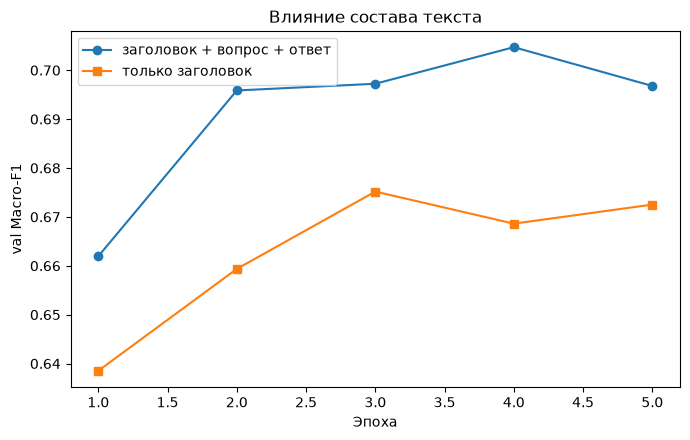

In [ ]:
# для сравнения — baseline на заголовках (несколько секунд)
t0 = time.time()
vec_t = TfidfVectorizer(max_features=10000)
clf_t = LogisticRegression(max_iter=1000).fit(vec_t.fit_transform(train_t["text"]), train_t["label"])
pred_t = clf_t.predict(vec_t.transform(test_t["text"]))
base_t_time = time.time() - t0

exp = pd.DataFrame([
    {"постановка": "DistilBERT, заголовок + вопрос + ответ", "Accuracy": test_res["test_accuracy"],
     "Macro-F1": test_res["test_f1_macro"], "время, с": bert_time},
    {"постановка": "DistilBERT, только заголовок", "Accuracy": test_res_t["test_accuracy"],
     "Macro-F1": test_res_t["test_f1_macro"], "время, с": title_time},
    {"постановка": "TF-IDF, заголовок + вопрос + ответ", "Accuracy": base_acc,
     "Macro-F1": base_f1, "время, с": base_time},
    {"постановка": "TF-IDF, только заголовок", "Accuracy": accuracy_score(test_t["label"], pred_t),
     "Macro-F1": f1_score(test_t["label"], pred_t, average="macro"), "время, с": base_t_time},
])
display(exp.round({"Accuracy": 4, "Macro-F1": 4, "время, с": 1}))

d_bert = test_res["test_f1_macro"] - test_res_t["test_f1_macro"]
d_tfidf = base_f1 - f1_score(test_t["label"], pred_t, average="macro")
print(f"Текст вопроса и лучший ответ добавляют DistilBERT {100 * d_bert:+.1f} п.п. Macro-F1, "
      f"TF-IDF — {100 * d_tfidf:+.1f} п.п.")
print(f"Один заголовок даёт DistilBERT {test_res_t['test_f1_macro'] / test_res['test_f1_macro']:.0%} "
      f"от качества полной модели")

plt.figure(figsize=(7, 4.5))
plt.plot(ep.index, ep["val Macro-F1"], "o-", label="заголовок + вопрос + ответ")
plt.plot(ep_t.index, ep_t["val Macro-F1"], "s-", label="только заголовок")
plt.xlabel("Эпоха"); plt.ylabel("val Macro-F1"); plt.title("Влияние состава текста")
plt.legend(); plt.tight_layout(); plt.show()

### Вывод по шагу 3.4

На одном заголовке DistilBERT даёт **Macro-F1 = 0.648** против 0.686 на полном тексте — разница всего **3.8 п.п.**, заголовок обеспечивает 94% качества полной модели. Значит, текст вопроса и лучший ответ полезны, но для трансформера немного: основную информацию о теме несёт заголовок.
Отчасти это следствие обрезки: заголовок короткий (медиана 15 токенов, не обрезается ни один), а полный текст обрезается в 63.9% случаев. Поэтому и в основной постановке DistilBERT видел в основном заголовок с началом вопроса, а лучший ответ ему почти не доставался.
Для TF-IDF картина обратная: без вопроса и ответа Macro-F1 падает на **12.8 п.п.** (0.581 → 0.454). Мешку слов нужно много слов, а по 5–10 словам заголовка совпадений со словарём мало. Трансформер же понимает смысл короткой фразы благодаря предобучению, поэтому на коротких текстах его преимущество над TF-IDF растёт: 19.4 п.п. против 10.5 п.п. на полном тексте.
Время обучения почти не изменилось (57 с): на такой небольшой выборке оно определяется числом шагов, а не длиной входа.

## Сводка чисел для выводов

In [ ]:
print(f"VARIANT={VARIANT}, SEED={SEED}, размеры: train={len(train_ds)}, val={len(val_ds)}, test={len(test_ds)}")
print(f"Классы train: min={dist['примеров'].min()}, max={dist['примеров'].max()}")
print(f"Длины: медиана={np.median(lengths):.0f}, обрезается при {MAX_LEN}: {share_long:.1%}")
print(f"Baseline: Acc={base_acc:.4f}, F1={base_f1:.4f}, время={base_time:.1f} с")
print(f"DistilBERT: Acc={test_res['test_accuracy']:.4f}, F1={test_res['test_f1_macro']:.4f}, время={bert_time:.1f} с")
print("Кривые:"); print(ep.round(4).to_string())
print(f"min val loss: эпоха {ep_min_loss}; max val F1: эпоха {ep_max_f1}; разрыв={gap:.4f}; ранняя остановка={stopped_early}")
print(f"Путаница: {LABELS[pi]} <-> {LABELS[pj]}: {sym[pi, pj]}")
print(f"Заголовок: Acc={test_res_t['test_accuracy']:.4f}, F1={test_res_t['test_f1_macro']:.4f}, время={title_time:.1f} с, тест совпал={same_test}")

VARIANT=10, SEED=1010, размеры: train=3500, val=750, test=750
Классы train: min=319, max=382
Длины: медиана=88, обрезается при 64: 63.9%
Baseline: Acc=0.5907, F1=0.5811, время=1.3 с
DistilBERT: Acc=0.6933, F1=0.6859, время=57.0 с
Кривые:
       train loss  val loss  val Accuracy  val Macro-F1
эпоха                                                  
1          1.6215    1.1119        0.6813        0.6619
2          0.9597    0.9760        0.6973        0.6959
3          0.7399    0.9574        0.7013        0.6972
4          0.5877    0.9580        0.7093        0.7047
5          0.4970    0.9680        0.7013        0.6968
min val loss: эпоха 3; max val F1: эпоха 4; разрыв=0.4710; ранняя остановка=False
Путаница: Science & Mathematics <-> Education & Reference: 20
Заголовок: Acc=0.6547, F1=0.6479, время=56.7 с, тест совпал=True
